# 03 · Anticipation check: picks before the stable release

Phase 5, a validity check on the pick-rate results in notebook 02, built in particular to test
whether anticipation explains the second patch's flat dose-response (slope 0.04 ± 0.31,
notebook 02 section 8). The estimation code is
`did.anticipation_*` in `src/spirometry/did.py`; this notebook calls it, prints the tables and
has the plotting code.

**The idea in plain terms.** A *difference-in-differences* (DiD) compares a changed card (the
*treated* card) with unchanged cards (the *controls*) before and after a patch. The controls
tell us what would have happened anyway. Picture two plants on the same windowsill. You feed
one of them, and the *difference* in their growth is the effect of the feeding, because the
sunlight hit both.

That only works if the "before" period is really before. Every change in this project showed
up on a *beta* build first, with public patch notes, before the stable release. The gap
between the two is the *lead time*. If players read the notes and started picking the card
differently while they were still playing the old stable build, part of the effect is already
inside the "before" period, and the DiD will understate the total change. That leak is called
**anticipation**: players react to a change before it arrives.

**The check.** Use only stable builds where the card is still the old card. Split them at the
date the change first appeared on a beta, and compare treated against controls before and
after that date. If picks jumped at the beta date, there was anticipation. If nothing moved
until the stable release, there wasn't. The output is one row per tweak: the move at the beta
date, whether the data can say anything, and that move next to notebook 02's main estimate.

**Terms used below**
- *treated / control*: the changed card / the unchanged cards of the same character.
- *lead time*: days from the first beta with the change to the stable release.
- *informative*: enough data on each side of the beta date to say anything (at least 2,000
  treated offers and 3 days with a treated offer on each side).
- *drift*: a slow trend in the treated card's pick rate that runs through the beta date. It
  looks like anticipation in the numbers but has no jump anywhere. The weekly plots are how you
  tell them apart.
- *date vs. build*: for the second patch the "before beta date" side is one build (v0.103.2)
  and the "after" side is mostly another (v0.103.3), which also fixed bugs. Section 7 checks
  whether the build change is doing the work.

Sections: 0 setup · 1 lead times · 2 which builds count as "old card" · 3 run the check ·
4 the table · 5 pre-release move against the main effect · 6 week by week · 7 date vs. build ·
8 how to read the results.

In [1]:
import os
import pathlib
import time

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Run from notebooks/ or the repo root. spirometry.did reads reference/ relative to the
# repo root, so move there.
ROOT = pathlib.Path.cwd()
if not (ROOT / "reference").exists():
    ROOT = ROOT.parent
os.chdir(ROOT)

from spirometry import did

REF = ROOT / "reference"
DB = ROOT / "data" / "runs" / "runs.duckdb"
OUT = ROOT / "data" / "analysis"          # git-ignored (data/)
OUT.mkdir(parents=True, exist_ok=True)
FORCE = False                              # True: refit instead of loading saved results

con = duckdb.connect(str(DB), read_only=True)
con.execute("SET enable_progress_bar = false")

plt.rcParams.update({
    "figure.figsize": (10, 4), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
    "lines.linewidth": 1.5, "lines.markersize": 4,
})
pd.set_option("display.width", 160, "display.max_columns", 40, "display.max_rows", 120)

TREATED_C, CONTROL_C, GREY = "#e8702a", "#2a6fdb", "#555555"   # same colors as 01 and 02
FIRST, SECOND = "first patch (v0.103.2)", "second patch (v0.107.1)"
PATCH_C = {FIRST: TREATED_C, SECOND: CONTROL_C}

info = dict(con.execute("SELECT key, value FROM build_info").fetchall())
for k in ["parser_version", "built_at_utc", "records_read", "pages_failed"]:
    print(f"{k:16s} {info.get(k, '(not in this build)')}")

parser_version   1.7.0
built_at_utc     2026-10-09T21:18:20+00:00
records_read     2069493
pages_failed     


## 1. Lead times

`reference/beta_exposure.csv` has, for each numeric tweak, the first beta that carried the
change and the stable release, and the days between them. The longer the lead time, the more
time players had to react to public patch notes while still on the old stable build. The second
patch's lead times are longer (14–56 days against 7–28), which is one reason it is a candidate
for anticipation.

In [2]:
TW = pd.read_csv(REF / "tweak_sizes.csv", dtype=str, keep_default_na=False).set_index("card_patch_id")
TW["window"] = np.where(TW.before_builds == "v0.99.1", FIRST, SECOND)

EX = pd.read_csv(REF / "beta_exposure.csv", dtype=str, keep_default_na=False)
EX["lead_days"] = pd.to_numeric(EX.lead_days, errors="coerce")
EX["window"] = EX.card_patch_id.map(TW.window)
display(EX.groupby("window").lead_days.describe()[["count", "min", "50%", "max"]])

,count,min,50%,max
window,,,,
first patch (v0.103.2),26.0,7.0,28.0,28.0
second patch (v0.107.1),17.0,14.0,28.0,56.0


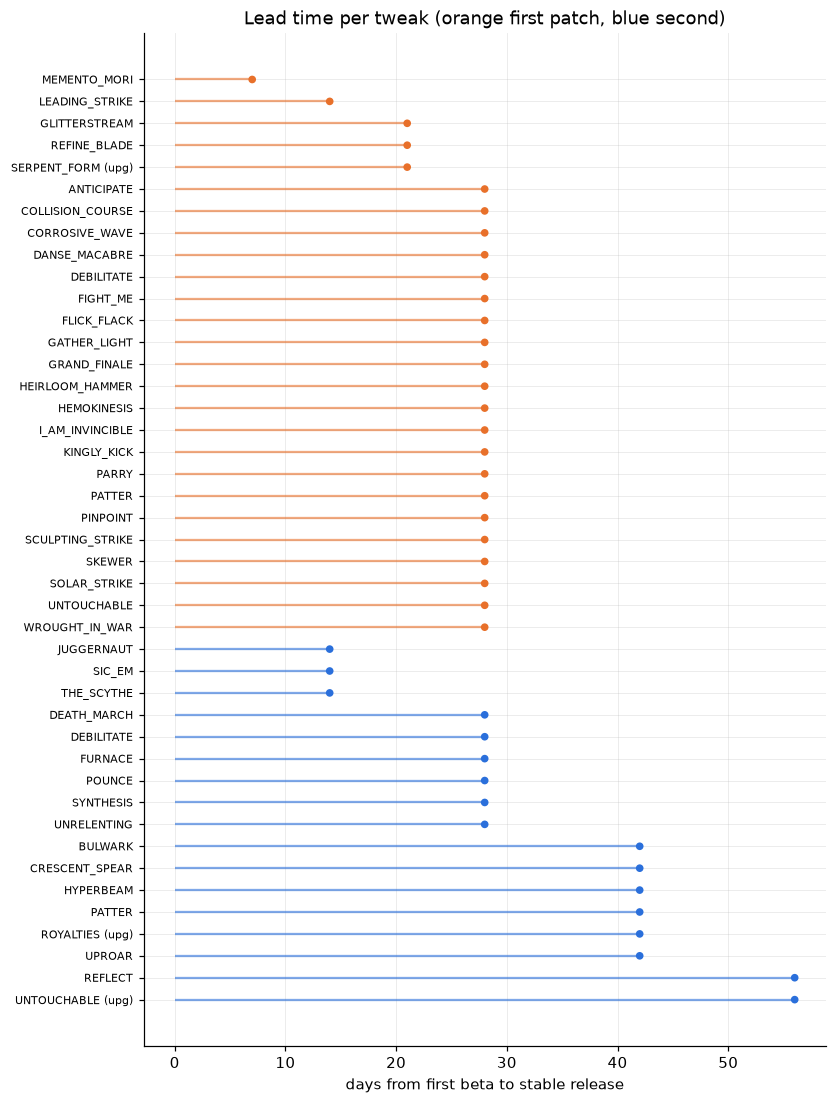

In [3]:
# Lead time per tweak. Dots further right = more days between the first beta and the stable release.
e = EX.sort_values(["window", "lead_days"]).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(8, 0.25 * len(e) + 1.2))
cols = [PATCH_C[w] for w in e.window]
ax.hlines(e.index, 0, e.lead_days, color=cols, lw=1.5, alpha=0.6)
ax.scatter(e.lead_days, e.index, c=cols, zorder=3)
ax.set_yticks(e.index, [f"{c}{' (upg)' if u == 'yes' else ''}" for c, u in zip(e.card_id, e.upgrade_only)],
              fontsize=7)
ax.invert_yaxis()
ax.set(xlabel="days from first beta to stable release", title="Lead time per tweak (orange first patch, blue second)")
plt.show()

## 2. Which builds count as "old card"

The check runs only on stable builds where the treated card *and every control* still have the
old version. `old_version_builds` finds them from `card_versions.csv`. For the first patch that
is v0.99.1 alone. For the second it is v0.103.2 and v0.103.3 (identical card versions on every
card; they differ only in a few bug fixes, listed second below, and those cards are dropped from
the controls).

In [4]:
for w, g in EX.groupby("window"):
    cpid = g.card_patch_id.iloc[0]
    builds, differ = did.old_version_builds(cpid, ref=REF)
    print(f"{w}  (example {cpid})")
    print(f"  old-version stable builds: {builds}")
    print(f"  cards with different bug-fix behavior between them: {differ}")

first patch (v0.103.2)  (example ANTICIPATE@v0.103.2/patch)
  old-version stable builds: ['v0.99.1']
  cards with different bug-fix behavior between them: []
second patch (v0.107.1)  (example BULWARK@v0.107.1/patch)
  old-version stable builds: ['v0.103.2', 'v0.103.3']
  cards with different bug-fix behavior between them: ['STARDUST', 'SUMMON_FORTH']


## 3. Run the check for every tweak

`did.anticipation_all` runs the check for the 43 solo-estimable tweaks. It takes the main
estimates from notebook 02's saved fits (`did_main.parquet`, all-weeks options) so the two
are compared on the same footing; **the fits and the run tables must come from the same build**,
so the cell warns when the saved file is older than `runs.duckdb`. Set `FORCE = True` (setup cell) to refit
instead of loading the saved `anticipation_main.parquet`; the cell also refits when that file is
older than `runs.duckdb`.

Upgrade-only tweaks are fit on upgraded offers and flagged (`upgrade_only`).

In [5]:
MAIN_PATH = OUT / "did_main.parquet"
main = pd.read_parquet(MAIN_PATH)
if main.index.name == "card_patch_id":
    main = main.reset_index()
assert {"card_patch_id", "beta", "se"} <= set(main.columns), main.columns.tolist()
if MAIN_PATH.stat().st_mtime < DB.stat().st_mtime:
    print("WARNING: did_main.parquet is older than runs.duckdb: rerun notebook 02 with FORCE = True first.")
print(f"{len(main)} tweaks in the saved main fits")

ANT_PATH = OUT / "anticipation_main.parquet"
stale = ANT_PATH.exists() and ANT_PATH.stat().st_mtime < DB.stat().st_mtime
if ANT_PATH.exists() and not FORCE and not stale:
    ant = pd.read_parquet(ANT_PATH)
else:
    if stale:
        print("saved anticipation file is older than runs.duckdb, refitting")
    t0 = time.time()
    ant = did.anticipation_all(con, main=main, ref=REF)
    ant.to_parquet(ANT_PATH)
    print(f"anticipation_all: {len(ant)} tweaks, {time.time() - t0:.0f} s")

ant["window"] = ant.card_patch_id.map(TW.window)
num = ["beta_postbeta", "se", "ci_lo", "ci_hi", "beta_main", "se_main", "ratio_to_main", "total_implied",
       "share_before_release", "pre_slope", "pre_slope_se", "week_gap", "lead_days",
       "n_treated_offers_pre", "n_treated_offers_post", "days_pre", "days_post", "main_postbeta_share"]
for c in num:
    if c in ant:
        ant[c] = pd.to_numeric(ant[c], errors="coerce")
print(ant.status.value_counts().to_string())
inf = ant[ant.status == "informative"].copy()
print(f"\n{len(inf)} of {len(ant)} tweaks are informative "
      f"(SPIROMETRY.md's rough count was 17; that count was never verified).")
print(inf.window.value_counts().to_string())

43 tweaks in the saved main fits


anticipation_all: 43 tweaks, 177 s
status
uninformative    27
informative      16

16 of 43 tweaks are informative (SPIROMETRY.md's rough count was 17; that count was never verified).
window
second patch (v0.107.1)    13
first patch (v0.103.2)      3


## 4. The table

Effects are in percentage points of pick rate.

- `beta_main_pp`: the main DiD from notebook 02 (change at the stable release).
- `postbeta_pp` (± `se_pp`): the change at the beta date, measured on old-card builds only.
  Near 0 means nothing moved before the release. Clearly above (below) 0 for a buff (nerf)
  means players started reacting early.
- `share_before_release`: `postbeta` divided by the total move implied. It is blank unless the
  main effect is clearly nonzero (|beta_main| > 2 se).
- `pre_slope_pp_wk`: the weekly trend in the gap *before* the beta date. A clear slope means the
  card was already drifting, which can fake anticipation.

In [6]:
def pp(s):
    return 100 * s

show = inf.assign(beta_main_pp=pp(inf.beta_main), postbeta_pp=pp(inf.beta_postbeta), se_pp=pp(inf.se),
                  pre_slope_pp_wk=pp(inf.pre_slope))
cols = ["card_id", "window", "lead_days", "n_treated_offers_pre", "n_treated_offers_post", "days_pre",
        "days_post", "beta_main_pp", "postbeta_pp", "se_pp", "share_before_release", "pre_slope_pp_wk",
        "week_gap"]
display(show.sort_values(["window", "postbeta_pp"])[[c for c in cols if c in show]]
        .style.format(precision=2))

un = ant[ant.status != "informative"]
print(f"\nNot informative ({len(un)}):")
display(un[[c for c in ["card_id", "window", "lead_days", "status", "reason"] if c in un]]
        .sort_values(["window", "card_id"]))

,card_id,window,lead_days,n_treated_offers_pre,n_treated_offers_post,days_pre,days_post,beta_main_pp,postbeta_pp,se_pp,share_before_release,pre_slope_pp_wk,week_gap
19,REFINE_BLADE,first patch (v0.103.2),21,7643,13384,9,21,5.18,-1.24,0.60,-0.28,1.68,2.06
8,GLITTERSTREAM,first patch (v0.103.2),21,7656,13499,9,21,3.53,-0.04,0.52,-0.01,-0.07,2.05
14,LEADING_STRIKE,first patch (v0.103.2),14,14523,9728,16,14,9.95,-0.02,0.56,-0.00,-1.54,2.15
42,UPROAR,second patch (v0.107.1),42,12843,21622,21,42,2.54,-2.47,0.40,-38.05,-1.32,4.88
26,BULWARK,second patch (v0.107.1),42,4933,6908,21,42,0.35,-1.49,0.99,nan,1.22,4.89
28,DEATH_MARCH,second patch (v0.107.1),28,6184,5768,35,28,1.99,-1.21,0.66,-1.53,-0.04,4.88
37,SIC_EM,second patch (v0.107.1),14,8842,2876,49,14,3.10,-1.05,0.98,-0.45,0.32,4.58
31,HYPERBEAM,second patch (v0.107.1),42,2214,3834,21,42,-0.52,-0.57,0.82,nan,0.13,4.87
35,REFLECT,second patch (v0.107.1),56,2061,9870,7,56,1.67,-0.25,1.22,nan,nan,4.51
29,DEBILITATE,second patch (v0.107.1),28,6057,5763,35,28,0.55,-0.25,0.82,nan,-0.38,4.88



Not informative (27):


,card_id,window,lead_days,status,reason
0,ANTICIPATE,first patch (v0.103.2),28,uninformative,1352 treated offers pre-beta (< 2000); 2 days ...
1,COLLISION_COURSE,first patch (v0.103.2),28,uninformative,1342 treated offers pre-beta (< 2000); 2 days ...
2,CORROSIVE_WAVE,first patch (v0.103.2),28,uninformative,250 treated offers pre-beta (< 2000); 2 days p...
3,DANSE_MACABRE,first patch (v0.103.2),28,uninformative,486 treated offers pre-beta (< 2000); 2 days p...
4,DEBILITATE,first patch (v0.103.2),28,uninformative,511 treated offers pre-beta (< 2000); 2 days p...
5,FIGHT_ME,first patch (v0.103.2),28,uninformative,553 treated offers pre-beta (< 2000); 2 days p...
6,FLICK_FLACK,first patch (v0.103.2),28,uninformative,1377 treated offers pre-beta (< 2000); 2 days ...
7,GATHER_LIGHT,first patch (v0.103.2),28,uninformative,1356 treated offers pre-beta (< 2000); 2 days ...
9,GRAND_FINALE,first patch (v0.103.2),28,uninformative,260 treated offers pre-beta (< 2000); 2 days p...
10,HEIRLOOM_HAMMER,first patch (v0.103.2),28,uninformative,225 treated offers pre-beta (< 2000); 2 days p...


## 5. Pre-release move against the main effect

One dot per informative tweak. x = the main effect (notebook 02). y = the change at the beta
date on old-card builds, with a 95% interval.

- **y near 0**: nothing moved before the stable release. The main DiD's "before" block is
  clean for that card.
- **y clearly on the same side as x**: players moved early. The main estimate is too small.
- The diagonal (y = x) is a landmark, not a target: a move equal to the main effect would mean
  most of the change happened before the release. A steady ramp from the beta date to the stable
  release gives roughly half to two-thirds of the main effect in the synthetic tests; a jump at
  the beta date can give more than the main effect.

A dot can also sit off zero because of drift; section 6 is the check for that.

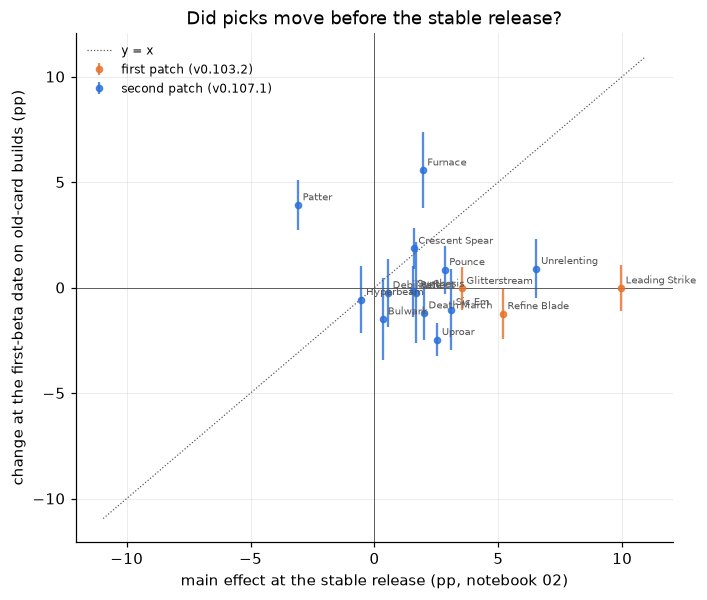

In [7]:
if inf.empty:
    print("no informative tweaks: nothing to plot")
else:
    fig, ax = plt.subplots(figsize=(7, 6))
    for w, g in inf.groupby("window"):
        ax.errorbar(pp(g.beta_main), pp(g.beta_postbeta), yerr=196 * g.se, fmt="o", color=PATCH_C[w],
                    ecolor=PATCH_C[w], alpha=0.8, capsize=0, label=w)
    for r in inf.itertuples():
        ax.annotate(r.card_id.replace("_", " ").title(), (100 * r.beta_main, 100 * r.beta_postbeta),
                    fontsize=6.5, xytext=(3, 3), textcoords="offset points", color=GREY)
    lim = np.nanmax(np.abs(np.r_[pp(inf.beta_main), pp(inf.beta_postbeta)])) * 1.1
    ax.plot([-lim, lim], [-lim, lim], color=GREY, lw=0.8, ls=":", label="y = x")
    ax.axhline(0, color=GREY, lw=0.6)
    ax.axvline(0, color=GREY, lw=0.6)
    ax.set(xlabel="main effect at the stable release (pp, notebook 02)",
           ylabel="change at the first-beta date on old-card builds (pp)",
           title="Did picks move before the stable release?")
    ax.legend(frameon=False, fontsize=8)
    plt.show()

In [8]:
# Where the ratios exist (|beta_main| > 2 se), by patch.
r = inf.dropna(subset=["share_before_release"])
print(f"{len(r)} of {len(inf)} informative tweaks have a clearly nonzero main effect (ratios are blank otherwise)")
if len(r):
    display(r.groupby("window")[["ratio_to_main", "share_before_release"]].agg(["count", "median"]))

12 of 16 informative tweaks have a clearly nonzero main effect (ratios are blank otherwise)


ratio_to_main           share_before_release          
                                count    median                count    median
window                                                                        
first patch (v0.103.2)              3 -0.012687                    3 -0.012793
second patch (v0.107.1)             9 -0.115881                    9  0.120692

## 6. Week by week

For the informative tweaks with the largest main effects: the gap between the treated card and
its controls, by week from the first-beta date (week 0 starts on that date; the dashed line
marks it). Week −1 is the reference (its dot is 0 by construction).

How to read a panel:
- **Flat at 0, then nothing until the stable release**: no anticipation.
- **A step at the dashed line**: players reacted to the beta notes.
- **A ramp that starts at the line**: gradual reaction.
- **A straight line running through the dashed line with no step**: drift, not anticipation.
  This is the case the single number in section 4 can't tell apart.

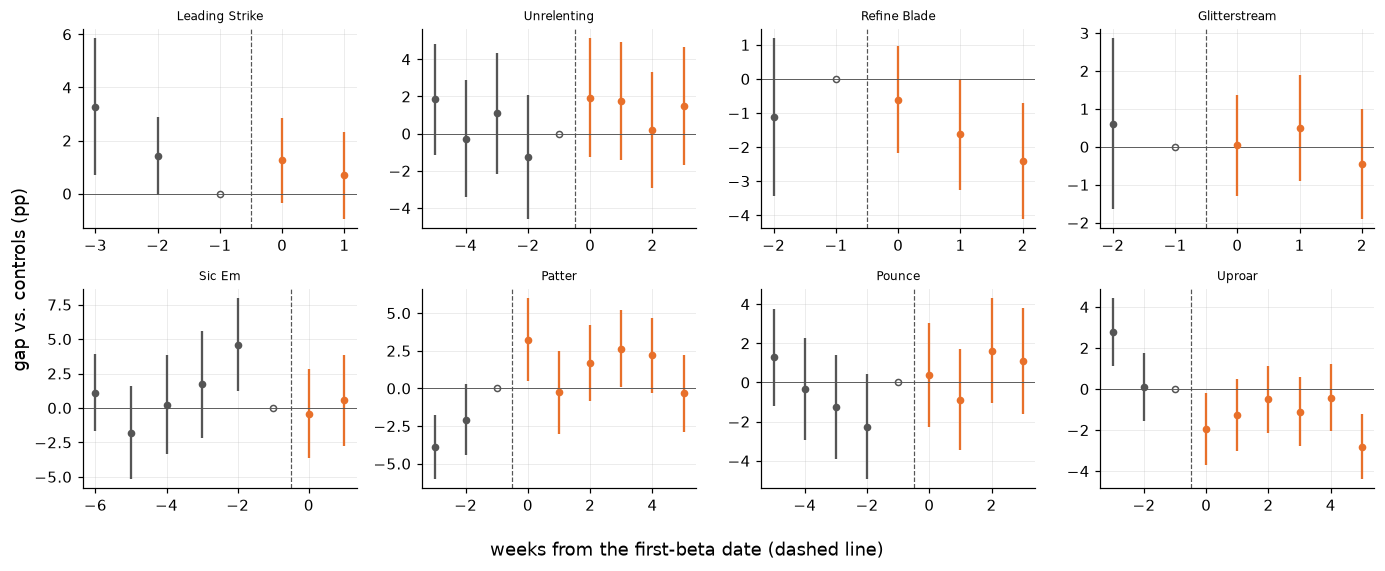

In [9]:
def plot_weekly(cpid, ax, builds=None):
    try:
        wk = did.anticipation_weekly(con, cpid, builds=builds, ref=REF)
    except Exception as e:                              # report and keep going
        ax.set_title(f"{cpid.split('@')[0]}: {type(e).__name__}", fontsize=8)
        return
    for blk, col in [("before", GREY), ("after", TREATED_C)]:
        g = wk[wk.block == blk]
        ax.errorbar(g.week, pp(g.coef), yerr=196 * g.se, fmt="o", color=col, ecolor=col, capsize=0)
    ax.plot(-1, 0, "o", mfc="white", color=GREY)        # the reference week
    ax.axvline(-0.5, color=GREY, lw=0.8, ls="--")
    ax.axhline(0, color=GREY, lw=0.6)
    ax.set_title(cpid.split("@")[0].replace("_", " ").title(), fontsize=8)

N_PANELS = 8
top = inf.reindex(inf.beta_main.abs().sort_values(ascending=False).index).head(N_PANELS)
if top.empty:
    print("no informative tweaks: nothing to plot")
else:
    ncol = 4
    nrow = -(-len(top) // ncol)
    fig, axes = plt.subplots(nrow, ncol, figsize=(3.2 * ncol, 2.6 * nrow), squeeze=False, sharey=False)
    for ax, cpid in zip(axes.ravel(), top.card_patch_id):
        plot_weekly(cpid, ax)
    for ax in axes.ravel()[len(top):]:
        ax.set_visible(False)
    fig.supxlabel("weeks from the first-beta date (dashed line)")
    fig.supylabel("gap vs. controls (pp)")
    fig.tight_layout()
    plt.show()

## 7. Date vs. build (second patch)

For the second patch, the split at the beta date is also a split between builds: earlier runs
are v0.103.2, later ones are mostly v0.103.3, which fixed bugs and had a different player mix.
If the build change moved the treated card relative to the controls, it would show up above as
"anticipation". The fix is to redo the check inside v0.103.2 alone. If the numbers shrink toward
0 there, the build change was doing the work. If they hold, the beta date is.

In [10]:
ONE_BUILD = ["v0.103.2"]      # the earlier of the two old-card builds (section 2)
sec = inf[inf.window.eq(SECOND) & inf.upgrade_only.ne("yes")]
mi = main.set_index("card_patch_id")
rows = []
for r in sec.itertuples():
    try:
        one = did.anticipation_check(con, r.card_patch_id, builds=ONE_BUILD, beta_main=mi.loc[r.card_patch_id, "beta"],
                                     se_main=mi.loc[r.card_patch_id, "se"], ref=REF)
        rows.append(dict(card_patch_id=r.card_patch_id, card=r.card_id, both_builds_pp=100 * r.beta_postbeta,
                         both_se_pp=100 * r.se, one_build_pp=100 * one["beta_postbeta"],
                         one_se_pp=100 * one["se"], one_build_status=one["status"]))
    except Exception as e:                              # report and keep going
        rows.append(dict(card_patch_id=r.card_patch_id, card=r.card_id, one_build_status=f"{type(e).__name__}: {e}"))
one_build = pd.DataFrame(rows)
display(one_build.style.format(precision=2) if len(one_build) else "no informative second-patch tweaks")

,card_patch_id,card,both_builds_pp,both_se_pp,one_build_pp,one_se_pp,one_build_status
0,BULWARK@v0.107.1/patch,BULWARK,-1.49,0.99,-2.02,1.17,informative
1,CRESCENT_SPEAR@v0.107.1/patch,CRESCENT_SPEAR,1.86,0.50,1.11,0.59,informative
2,DEATH_MARCH@v0.107.1/patch,DEATH_MARCH,-1.21,0.66,0.93,1.01,uninformative
3,DEBILITATE@v0.107.1/patch,DEBILITATE,-0.25,0.82,-0.78,1.19,uninformative
4,FURNACE@v0.107.1/patch,FURNACE,5.57,0.93,2.88,1.35,uninformative
5,HYPERBEAM@v0.107.1/patch,HYPERBEAM,-0.57,0.82,-1.34,0.94,uninformative
6,PATTER@v0.107.1/patch,PATTER,3.92,0.60,4.23,0.72,informative
7,POUNCE@v0.107.1/patch,POUNCE,0.85,0.58,0.26,0.84,informative
8,REFLECT@v0.107.1/patch,REFLECT,-0.25,1.22,0.96,1.28,informative
9,SIC_EM@v0.107.1/patch,SIC_EM,-1.05,0.98,-19.08,5.10,uninformative


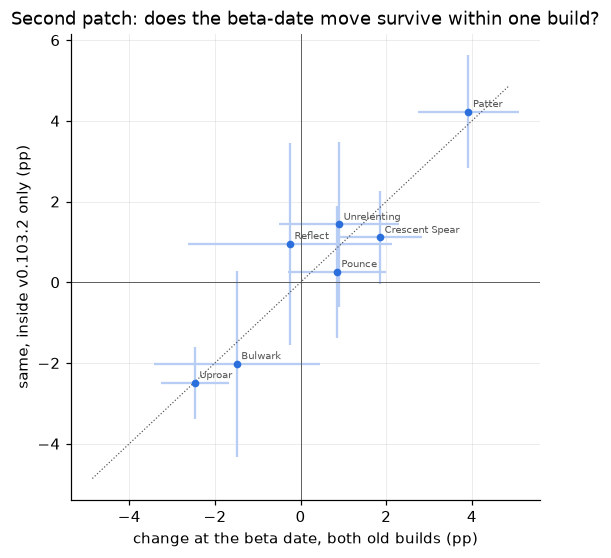

In [11]:
ok = one_build[one_build.get("one_build_status", pd.Series(dtype=str)).eq("informative")] if len(one_build) else one_build
if len(ok):
    fig, ax = plt.subplots(figsize=(5.5, 5.5))
    ax.errorbar(ok.both_builds_pp, ok.one_build_pp, xerr=1.96 * ok.both_se_pp, yerr=1.96 * ok.one_se_pp,
                fmt="o", color=CONTROL_C, ecolor="#b7cdf3", capsize=0)
    for r in ok.itertuples():
        ax.annotate(r.card.replace("_", " ").title(), (r.both_builds_pp, r.one_build_pp), fontsize=6.5,
                    xytext=(3, 3), textcoords="offset points", color=GREY)
    lim = np.nanmax(np.abs(np.r_[ok.both_builds_pp, ok.one_build_pp])) * 1.15
    ax.plot([-lim, lim], [-lim, lim], color=GREY, lw=0.8, ls=":")
    ax.axhline(0, color=GREY, lw=0.6)
    ax.axvline(0, color=GREY, lw=0.6)
    ax.set(xlabel="change at the beta date, both old builds (pp)", ylabel="same, inside v0.103.2 only (pp)",
           title="Second patch: does the beta-date move survive within one build?")
    plt.show()
else:
    print("nothing to plot (no informative second-patch tweak inside one build)")

## 8. How to read the results

- A dot at y ≈ 0 in section 5 means nothing moved before the stable release: the main DiD's
  "before" block is clean for that card.
- A slow drift through the beta date also gives a nonzero number in section 4, with no step
  anywhere. The weekly panels in section 6 tell the two apart: a step or a ramp that starts at
  the dashed line is a reaction to the beta notes; a straight line running through it is drift.
- Section 7 is needed only for the second patch. There the split at the beta date is also a
  split between builds (v0.103.2 before, mostly v0.103.3 after), so a build change can look like
  anticipation. For the first patch the only old-card build is v0.99.1 (section 2), so the split
  stays inside one build.